# NumPy 2: Forma, ejes y `dtype`

_Autor: Milena Barrios_

Este notebook enseña a leer la forma y el tipo de número de un array, qué representa cada eje del cubo de fotos de una estrella, y cómo el tipo de número decide cuánta memoria ocupa y qué tan exacta sale una cuenta. Cubre:

1. Dimensiones: de una fila a un cubo
2. Qué es cada eje del cubo
3. El tipo de número (`dtype`) y la memoria
4. Precisión: por qué la suma no dio exacta

## 0. Prerrequisitos

Para correr este notebook, deben asegurarse de haber creado el virtual environment de python siguiendo las instrucciones del README. Una vez creado, selecciona el kernel del notebook.

Los datos están en la carpeta `data/`, al lado de esta carpeta `notebooks/`.

Para instalar python, el manejador de paquetes UV, los ambientes de conda y configurar Visual Studio Code para correr y editar Jupyter Notebooks en él, revisen los siguientes recursos:

- [Cómo instalar Anaconda y Jupyter](https://youtu.be/YzOLOlH1jQk?si=2hFk6aAh8gCoMvuo)
- [Instalación de UV](https://youtu.be/TJor7z8g8FA?si=QT2XVKeC29dYyDts)
- [VS Code + Jupyter Notebooks](https://youtu.be/rL1usXq4bgE?si=2b5REnUzVBMDxWfF)

### Prompts de profundización

Al final de cada sección hay unas preguntas para que explores y profundices más.

## 1. Dimensiones: de una fila a un cubo

Cargamos los tres archivos de la serie. Cada uno tiene una cantidad distinta de dimensiones.

In [1]:
import numpy as np

cube = np.load("../data/flux_cube.npy")
time = np.load("../data/time.npy")
mask = np.load("../data/aperture_mask.npy")

`ndim` dice cuántas dimensiones tiene un array; `shape`, cuántos elementos hay en cada una.

In [2]:
print("time:", time.ndim, time.shape) # One dimension

time: 1 (1440,)


In [3]:
print("mask:", mask.ndim, mask.shape) # Two dimensions (rows and columns)

mask: 2 (11, 11)


In [4]:
print("cube:", cube.ndim, cube.shape) # Three dimensions (many tables stacked)

cube: 3 (1440, 11, 11)


`size` es el total de números del array: el producto de su forma.

In [5]:
# I compare size with the product of the shape
print(cube.size)
print(1440 * 11 * 11)

174240
174240


**Prompts de profundización:**

- `¿Qué diferencia hay entre ndim, shape y size en un array de NumPy?`
- `¿Por qué la forma de un array de una dimensión se escribe (1440,) con una coma?`
- `¿Cómo se representan en NumPy una imagen a color o un video?`

## 2. Qué es cada eje del cubo

A cada dimensión se le llama **eje**, y se numeran desde 0. En el cubo, el eje 0 es el tiempo (cuál foto), el eje 1 son las filas y el eje 2 son las columnas. Para comprobar el eje 0: hay un tiempo por cada foto.

In [6]:
# I can check that there is one time per photo
print(len(time))
print(cube.shape[0])

1440
1440


Cada `[ ]` quita el primer número de la forma:

In [7]:
print(cube[0].shape) # This is the first photo: 11 rows, 11 columns

(11, 11)


In [8]:
print(cube[0][5].shape) # This is the fifth row: 11 numbers

(11,)


In [9]:
print(cube[0][5][5].shape) # It is just a number

()


In [10]:
# I read the single number at row 5, column 5 of the first photo
print(cube[0][5][5])

7896.526


In [11]:
from plot_helpers import plot_frame 

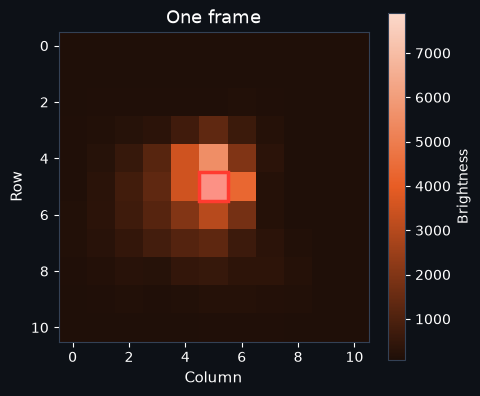

In [12]:
# I show the same pixel highlighted in red on the image
plot_frame(cube[0], highlight=(5,5))

**Prompts de profundización:**

- `¿Qué significa "eje" (axis) en un array de NumPy?`
- `¿Por qué NumPy empieza a numerar los ejes desde 0?`
- `¿En qué orden suelen guardarse los ejes de un video o una serie de imágenes en ciencia de datos?`

## 3. El tipo de número (`dtype`) y la memoria

Todo array tiene un `dtype`: el tipo de número que guarda. Cada archivo de la serie guarda uno distinto.

In [13]:
# I print the type of number of each file
print("time:", time.dtype)
print("mask:", mask.dtype)
print("cube:", cube.dtype)

time: float64
mask: bool
cube: float32


`itemsize` dice cuántos bytes ocupa cada número:

In [14]:
# I print the bytes used by each number
print("time:", time.itemsize)
print("mask:", mask.itemsize)
print("cube:", cube.itemsize)

time: 8
mask: 1
cube: 4


`nbytes` es la memoria total del array: cuántos números hay por lo que ocupa cada uno.

In [15]:
# I check that nbytes is size times itemsize
print(cube.nbytes)
print(cube.size * cube.itemsize)

696960
696960


Con `astype` se puede convertir el array a otro tipo. El mismo cubo en `float64`:

In [16]:
# I convert the cube to float64: it makes a new array, cube stays float32
cube64 = cube.astype(np.float64)

In [17]:
print(cube64.dtype)
print(cube64.nbytes)

float64
1393920


NumPy elige el tipo a partir de lo que le damos:

In [18]:
# I let NumPy choose the type from what I give it!
print(np.array([1, 2, 3]).dtype)
print(np.array([1, 2, 3.5]).dtype)
print(np.array([1, "dos", 3.0]).dtype)

int64
float64
<U32


**Prompts de profundización:**

- `¿Qué tipos de datos (dtype) tiene NumPy y cuándo conviene usar cada uno?`
- `¿Por qué un array de NumPy ocupa menos memoria que una lista de Python con los mismos números?`
- `¿Qué hace astype en NumPy y qué riesgos tiene convertir entre tipos?`

## 4. Precisión: por qué la suma no dio exacta

La diferencia entre el bucle y NumPy del notebook anterior tiene dos causas distintas: cuántas cifras caben en el tipo de número, y en qué orden se suma.

### 4.1 Parte A: qué números existen en cada tipo

In [19]:
# I ask how many digits each type guarantees
print(np.finfo(np.float32).precision)
print(np.finfo(np.float64).precision)

6
15


Las cifras se gastan primero en la parte entera. Cerca de 60.000, ¿qué pasa si le sumamos cantidades pequeñas? A la izquierda, en `float32`; a la derecha, en `float64`:

In [20]:
for step in [0.001, 0.002, 0.003, 0.004, 0.005, 0.006, 0.007, 0.008]:
    print(step, np.float32(60000 + step), np.float64(60000 + step))

0.001 60000.0 60000.001
0.002 60000.004 60000.002
0.003 60000.004 60000.003
0.004 60000.004 60000.004
0.005 60000.004 60000.005
0.006 60000.008 60000.006
0.007 60000.008 60000.007
0.008 60000.008 60000.008


`float32` avanza a escalones. `np.spacing` dice el tamaño del escalón:

In [21]:
# I measure the step size near 60000, and near a big date (in hours)
print(np.spacing(np.float32(60000)))
print(np.spacing(np.float32(2458363)) * 24)

0.00390625
6.0


El valor exacto de la suma de la primera foto, calculado en `float64`, y lo más cerca que puede llegar `float32`:

In [22]:
frame = cube[0]
frame64 = frame.astype(np.float64)
# I sum the first photo in float64 and then round it to float32
print(np.sum(frame64))
print(np.float32(np.sum(frame64)))

60327.94861602783
60327.95


### 4.2 Parte B: el orden en que se suma

La misma suma del notebook anterior, en `float32`:

In [23]:
# I repeat the sum from video 1 with the loop and with NumPy
total = 0.0
for row in frame:
    for value in row:
        total += value

print(total)
print(np.sum(frame))

60327.945
60327.953


Y en `float64`:

In [24]:
# I repeat both sums, now in float64
total = 0.0
for row in frame64:
    for value in row:
        total += value

print(total)
print(np.sum(frame64))

60327.94861602783
60327.94861602783


**Prompts de profundización:**

- `¿Cómo representa un computador los números decimales (punto flotante) y por qué no son exactos?`
- `¿Por qué sumar los mismos números en distinto orden puede dar resultados distintos en punto flotante?`
- `¿Cuándo vale la pena usar float64 en vez de float32 en ciencia de datos y machine learning?`

## 5. ¿Qué viene?

Este es el brillo del píxel de la estrella en las primeras tres fotos. ¿Cómo sacarlo en las 1440 fotos de una vez? Eso es el siguiente notebook.

In [25]:
# I print the same pixel in the first three photos
print(cube[0][5][5])
print(cube[1][5][5])
print(cube[2][5][5])

7896.526
7873.591
7896.312


## Referencias

- NumPy Developers. *NumPy documentation*. https://numpy.org/doc/stable/
- NumPy Developers. *Data types*. https://numpy.org/doc/stable/user/basics.types.html
- NumPy Developers. *numpy.finfo*. https://numpy.org/doc/stable/reference/generated/numpy.finfo.html

---

*Última actualización: octubre 2026*